## 1. Imports and environment check

This notebook uses TensorFlow/Keras, NumPy, Pandas, and Matplotlib. It does not require PyTorch or a GPU.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("NumPy:", np.__version__)
print("Available devices:", tf.config.list_physical_devices())


TensorFlow: 2.21.0
Keras: 3.15.1
NumPy: 2.5.4
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Create a retail-style dataset

We simulate three broad customer patterns. The groups overlap slightly, as customer behaviour is not perfectly separated in real life.

Features:
- `avg_basket_value`: average spend per transaction, in arbitrary currency units.
- `monthly_visits`: number of store visits per month.

The group labels are used only to create and inspect the simulated data. The GAN and VAE will train on the two numerical features, not on the labels.

In [2]:
np.random.seed(42)
tf.random.set_seed(42)

n_per_group = 700

# Group 1: frequent visits, lower average basket
group_1 = np.column_stack([
    np.random.normal(450, 75, n_per_group),
    np.random.normal(8, 1.8, n_per_group)
])

# Group 2: fewer visits, higher average basket
group_2 = np.column_stack([
    np.random.normal(1250, 180, n_per_group),
    np.random.normal(3.5, 1.1, n_per_group)
])

# Group 3: moderate visits and basket value
group_3 = np.column_stack([
    np.random.normal(800, 120, n_per_group),
    np.random.normal(5.5, 1.4, n_per_group)
])

real_data = np.vstack([group_1, group_2, group_3]).astype("float32")
real_data[:, 0] = np.clip(real_data[:, 0], 100, 2000)
real_data[:, 1] = np.clip(real_data[:, 1], 1, 15)

retail_df = pd.DataFrame(
    real_data,
    columns=["avg_basket_value", "monthly_visits"]
)

display(retail_df.head())
print("Dataset shape:", retail_df.shape)
display(retail_df.describe().round(2))


,avg_basket_value,monthly_visits
0,487.253571,7.059099
1,439.630188,9.888217
2,498.576630,6.732182
3,564.227234,5.464770
4,432.438507,5.198068


Dataset shape: (2100, 2)


,avg_basket_value,monthly_visits
count,2100.00,2100.00
mean,835.31,5.70
std,356.85,2.38
min,206.90,1.00
25%,496.18,3.88
50%,792.43,5.39
75%,1142.92,7.35
max,1824.76,12.74


## 3. Visualize and scale the data

Both neural networks train more reliably when input features have similar numerical scales. We standardize each feature using the mean and standard deviation of the training data.

For this compact demonstration, the full synthetic dataset is used as the training set.

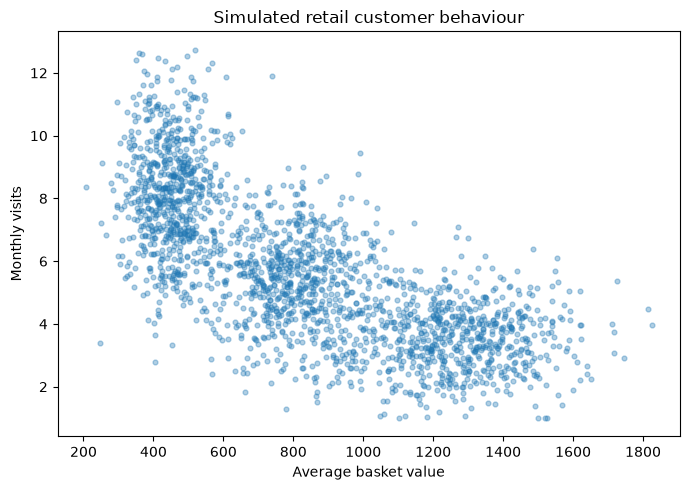

Scaled data shape: (2100, 2)
Feature means after scaling: [ 0. -0.]
Feature stds after scaling: [1. 1.]


In [3]:
feature_mean = real_data.mean(axis=0)
feature_std = real_data.std(axis=0)

scaled_data = (real_data - feature_mean) / feature_std
scaled_data = scaled_data.astype("float32")

plt.figure(figsize=(7, 5))
plt.scatter(real_data[:, 0], real_data[:, 1], alpha=0.35, s=12)
plt.xlabel("Average basket value")
plt.ylabel("Monthly visits")
plt.title("Simulated retail customer behaviour")
plt.tight_layout()
plt.show()

print("Scaled data shape:", scaled_data.shape)
print("Feature means after scaling:", scaled_data.mean(axis=0).round(3))
print("Feature stds after scaling:", scaled_data.std(axis=0).round(3))


# Part A — Generative Adversarial Network (GAN)

## 4. How a GAN works

A GAN contains two networks:

- **Generator:** takes random noise as input and tries to create realistic-looking customer profiles.
- **Discriminator:** receives real or generated profiles and predicts whether each profile is real.

They compete during training:
1. The Discriminator learns to distinguish real samples from generated samples.
2. The Generator learns to fool the Discriminator.
3. Ideally, generated samples become difficult for the Discriminator to distinguish from real samples.

The noise vector is often called the **latent vector** or **z**.

In [4]:
# GAN configuration
NOISE_DIM = 8
GAN_EPOCHS = 300
BATCH_SIZE = 64

# Generator: random noise -> two retail features
generator = keras.Sequential(
    [
        layers.Input(shape=(NOISE_DIM,)),
        layers.Dense(32),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dense(64),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dense(2)
    ],
    name="retail_generator"
)

# Discriminator: two retail features -> real/fake logit
discriminator = keras.Sequential(
    [
        layers.Input(shape=(2,)),
        layers.Dense(64),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dense(32),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dense(1)
    ],
    name="retail_discriminator"
)

generator.summary()
discriminator.summary()


Model: "retail_generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ dense (Dense)                 │ (None, 32)            │          288 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ leaky_re_lu (LeakyReLU)       │ (None, 32)            │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_1 (Dense)               │ (None, 64)            │        2,112 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ leaky_re_lu_1 (LeakyReLU)     │ (None, 64)            │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_2 (Dense)               │ (None, 2)             │          130 │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 2,530 (9.88 KB)

 Trainable params: 2,530 (9.88 KB)

 Non-trainable params: 0 (0.00 B)

Model: "retail_discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ dense_3 (Dense)               │ (None, 64)            │          192 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ leaky_re_lu_2 (LeakyReLU)     │ (None, 64)            │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_4 (Dense)               │ (None, 32)            │        2,080 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ leaky_re_lu_3 (LeakyReLU)     │ (None, 32)            │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_5 (Dense)               │ (None, 1)             │           33 │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 2,305 (9.00 KB)

 Trainable params: 2,305 (9.00 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Train the GAN

We use `BinaryCrossentropy(from_logits=True)` because the Discriminator returns an unbounded logit rather than a sigmoid probability.

The training loop uses `tf.GradientTape`:
- Update the Discriminator using real and generated samples.
- Update the Generator using the Discriminator's response to generated samples.

GAN training can be unstable. The loss values do not always decrease smoothly, so we also inspect generated samples visually.

In [6]:
cross_entropy = keras.losses.BinaryCrossentropy(from_logits=True)

generator_optimizer = keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
discriminator_optimizer = keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)

@tf.function
def train_gan_step(real_batch):
    batch_size = tf.shape(real_batch)[0]
    noise = tf.random.normal([batch_size, NOISE_DIM])

    # -------------------------
    # Train Discriminator
    # -------------------------
    with tf.GradientTape() as disc_tape:
        generated_batch = generator(noise, training=True)

        real_logits = discriminator(real_batch, training=True)
        fake_logits = discriminator(generated_batch, training=True)

        real_loss = cross_entropy(tf.ones_like(real_logits), real_logits)
        fake_loss = cross_entropy(tf.zeros_like(fake_logits), fake_logits)
        disc_loss = real_loss + fake_loss

    disc_gradients = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )
    discriminator_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    # -------------------------
    # Train Generator
    # -------------------------
    noise = tf.random.normal([batch_size, NOISE_DIM])

    with tf.GradientTape() as gen_tape:
        generated_batch = generator(noise, training=True)
        fake_logits = discriminator(generated_batch, training=True)
        gen_loss = cross_entropy(tf.ones_like(fake_logits), fake_logits)

    gen_gradients = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )
    generator_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )

    return gen_loss, disc_loss


dataset = (
    tf.data.Dataset.from_tensor_slices(scaled_data)
    .shuffle(buffer_size=len(scaled_data))
    .batch(BATCH_SIZE, drop_remainder=True)
)

gan_gen_losses = []
gan_disc_losses = []

for epoch in range(1, GAN_EPOCHS + 1):
    gen_epoch_loss = []
    disc_epoch_loss = []

    for real_batch in dataset:
        gen_loss, disc_loss = train_gan_step(real_batch)
        gen_epoch_loss.append(float(gen_loss))
        disc_epoch_loss.append(float(disc_loss))

    gan_gen_losses.append(np.mean(gen_epoch_loss))
    gan_disc_losses.append(np.mean(disc_epoch_loss))

    if epoch % 50 == 0:
        print(
            f"Epoch {epoch}/{GAN_EPOCHS} | "
            f"Generator loss: {gan_gen_losses[-1]:.4f} | "
            f"Discriminator loss: {gan_disc_losses[-1]:.4f}"
        )


Epoch 50/300 | Generator loss: 0.6925 | Discriminator loss: 1.3891
Epoch 100/300 | Generator loss: 0.7030 | Discriminator loss: 1.3841
Epoch 150/300 | Generator loss: 0.6987 | Discriminator loss: 1.3852
Epoch 200/300 | Generator loss: 0.7014 | Discriminator loss: 1.3857
Epoch 250/300 | Generator loss: 0.6851 | Discriminator loss: 1.3875
Epoch 300/300 | Generator loss: 0.6958 | Discriminator loss: 1.3874


## 6. Inspect GAN training losses

In [ ]:
plt.figure(figsize=(9, 4))
plt.plot(gan_gen_losses, label="Generator loss")
plt.plot(gan_disc_losses, label="Discriminator loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN training losses")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Generate synthetic retail profiles with the GAN

The Generator produces values in standardized feature space. We reverse the standardization to return to the original units.

In [ ]:
n_generated = 1000

noise = tf.random.normal([n_generated, NOISE_DIM])
gan_generated_scaled = generator(noise, training=False).numpy()

gan_generated = gan_generated_scaled * feature_std + feature_mean
gan_generated[:, 0] = np.clip(gan_generated[:, 0], 0, None)
gan_generated[:, 1] = np.clip(gan_generated[:, 1], 0, None)

gan_df = pd.DataFrame(
    gan_generated,
    columns=["avg_basket_value", "monthly_visits"]
)

display(gan_df.head())
display(gan_df.describe().round(2))


## 8. Compare real and GAN-generated profiles

Compare the overall distribution and the scatter pattern. A good-looking plot is only a first check; more formal validation is needed before using synthetic data in a business workflow.

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(
    real_data[:, 0], real_data[:, 1],
    alpha=0.25, s=10, label="Real (simulated) data"
)
plt.scatter(
    gan_generated[:, 0], gan_generated[:, 1],
    alpha=0.25, s=10, label="GAN-generated data"
)
plt.xlabel("Average basket value")
plt.ylabel("Monthly visits")
plt.title("Real vs GAN-generated retail profiles")
plt.legend()
plt.tight_layout()
plt.show()


# Part B — Variational Autoencoder (VAE)

## 9. How a VAE works

A VAE has two main networks:

- **Encoder:** maps an input to the parameters of a latent probability distribution, usually a mean (`z_mean`) and log variance (`z_log_var`).
- **Decoder:** takes a sampled latent vector and reconstructs the original input.

The VAE is trained with two losses:
1. **Reconstruction loss:** encourages the reconstructed profile to resemble the input.
2. **KL divergence loss:** encourages the learned latent distribution to stay close to a standard normal distribution.

The reparameterization trick allows gradients to flow through sampling:

`z = z_mean + exp(0.5 * z_log_var) * epsilon`

where `epsilon` is sampled from a standard normal distribution.

In [ ]:
LATENT_DIM = 2

# Encoder
vae_inputs = keras.Input(shape=(2,), name="vae_input")
x = layers.Dense(32, activation="relu")(vae_inputs)
x = layers.Dense(16, activation="relu")(x)

z_mean = layers.Dense(LATENT_DIM, name="z_mean")(x)
z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(x)

class Sampling(layers.Layer):
    def call(self, inputs):
        mean, log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(mean))
        return mean + tf.exp(0.5 * log_var) * epsilon

z = Sampling(name="sampling")([z_mean, z_log_var])

encoder = keras.Model(
    vae_inputs,
    [z_mean, z_log_var, z],
    name="retail_vae_encoder"
)

# Decoder
latent_inputs = keras.Input(shape=(LATENT_DIM,), name="latent_input")
x = layers.Dense(16, activation="relu")(latent_inputs)
x = layers.Dense(32, activation="relu")(x)
decoder_outputs = layers.Dense(2, name="reconstructed_features")(x)

decoder = keras.Model(
    latent_inputs,
    decoder_outputs,
    name="retail_vae_decoder"
)

encoder.summary()
decoder.summary()


## 10. Define and train the VAE

We implement a custom training step so reconstruction and KL losses are calculated explicitly. This is compatible with the TensorFlow/Keras workflow used in this notebook.

In [ ]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name="loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker
        ]

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            mean, log_var, sampled_z = self.encoder(data, training=True)
            reconstruction = self.decoder(sampled_z, training=True)

            # Sum squared error across the two features, then average batch
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(tf.square(data - reconstruction), axis=1)
            )

            # KL divergence from learned Gaussian to standard normal
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + log_var - tf.square(mean) - tf.exp(log_var),
                    axis=1
                )
            )

            total_loss = reconstruction_loss + kl_loss

        gradients = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(
            zip(gradients, self.trainable_variables)
        )

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result()
        }

    def call(self, inputs):
        _, _, sampled_z = self.encoder(inputs)
        return self.decoder(sampled_z)


vae = VAE(encoder, decoder, name="retail_vae")
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001))

vae_history = vae.fit(
    scaled_data,
    epochs=60,
    batch_size=64,
    shuffle=True,
    verbose=1
)


## 11. Plot VAE losses

In [ ]:
plt.figure(figsize=(9, 4))
plt.plot(vae_history.history["loss"], label="Total loss")
plt.plot(
    vae_history.history["reconstruction_loss"],
    label="Reconstruction loss"
)
plt.plot(vae_history.history["kl_loss"], label="KL divergence")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE training losses")
plt.legend()
plt.tight_layout()
plt.show()


## 12. Reconstruct customer profiles

A reconstruction is the Decoder's attempt to reproduce an input profile after it passes through the Encoder's latent representation.

In [ ]:
z_mean_values, z_log_var_values, z_values = encoder.predict(
    scaled_data[:500],
    verbose=0
)

reconstructed_scaled = decoder.predict(z_values, verbose=0)
reconstructed = reconstructed_scaled * feature_std + feature_mean
original_subset = real_data[:500]

reconstruction_mae = np.mean(
    np.abs(original_subset - reconstructed)
)

print(f"Reconstruction MAE across both features: {reconstruction_mae:.2f}")

plt.figure(figsize=(8, 5))
plt.scatter(
    original_subset[:, 0], original_subset[:, 1],
    alpha=0.35, s=12, label="Original profiles"
)
plt.scatter(
    reconstructed[:, 0], reconstructed[:, 1],
    alpha=0.35, s=12, label="VAE reconstructions"
)
plt.xlabel("Average basket value")
plt.ylabel("Monthly visits")
plt.title("Original vs VAE-reconstructed profiles")
plt.legend()
plt.tight_layout()
plt.show()


## 13. Generate new profiles with the VAE

Sample latent vectors from a standard normal distribution and pass them through the trained Decoder.

In [ ]:
n_vae_generated = 1000

latent_samples = np.random.normal(
    size=(n_vae_generated, LATENT_DIM)
).astype("float32")

vae_generated_scaled = decoder.predict(latent_samples, verbose=0)
vae_generated = vae_generated_scaled * feature_std + feature_mean

vae_generated[:, 0] = np.clip(vae_generated[:, 0], 0, None)
vae_generated[:, 1] = np.clip(vae_generated[:, 1], 0, None)

vae_df = pd.DataFrame(
    vae_generated,
    columns=["avg_basket_value", "monthly_visits"]
)

display(vae_df.head())
display(vae_df.describe().round(2))

plt.figure(figsize=(8, 6))
plt.scatter(
    real_data[:, 0], real_data[:, 1],
    alpha=0.22, s=10, label="Real (simulated) data"
)
plt.scatter(
    vae_generated[:, 0], vae_generated[:, 1],
    alpha=0.25, s=10, label="VAE-generated data"
)
plt.xlabel("Average basket value")
plt.ylabel("Monthly visits")
plt.title("Real vs VAE-generated retail profiles")
plt.legend()
plt.tight_layout()
plt.show()


## 14. GAN vs VAE — comparison

| Aspect | GAN | VAE |
|---|---|---|
| Main components | Generator + Discriminator | Encoder + Decoder |
| Learning idea | Adversarial competition | Probabilistic latent representation |
| Training objective | Generator and Discriminator losses | Reconstruction + KL divergence |
| Sampling | Feed random noise to Generator | Sample latent vector and decode |
| Common challenge | Training instability or mode collapse | Reconstructions can be overly smooth |
| Useful inspection | Real/fake distributions and diversity | Reconstruction quality and latent space |

Neither approach is automatically better. The right choice depends on the data, the objective, and how generated data will be evaluated.

## 15. Save the models and generated sample data

The models are saved in the project's `Models` folder. Generated CSV files are saved in the project-level `Data` folder. The notebook's current working directory is expected to be `RetailMind-AI/Notebooks`.

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
MODELS_DIR = PROJECT_ROOT / "Models"
DATA_DIR = PROJECT_ROOT / "Data"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

generator.save(MODELS_DIR / "retail_gan_generator.keras")
discriminator.save(MODELS_DIR / "retail_gan_discriminator.keras")
encoder.save(MODELS_DIR / "retail_vae_encoder.keras")
decoder.save(MODELS_DIR / "retail_vae_decoder.keras")

gan_df.to_csv(DATA_DIR / "gan_synthetic_retail_profiles.csv", index=False)
vae_df.to_csv(DATA_DIR / "vae_synthetic_retail_profiles.csv", index=False)

print("Saved GAN Generator and Discriminator to:", MODELS_DIR.resolve())
print("Saved VAE Encoder and Decoder to:", MODELS_DIR.resolve())
print("Saved generated CSV files to:", DATA_DIR.resolve())


## 16. Day 11 summary and completion checklist

### What you implemented
- Created a simulated retail customer-behaviour dataset.
- Built and trained a GAN with a Generator and Discriminator.
- Generated synthetic customer profiles with the GAN.
- Built and trained a VAE with an Encoder, latent distribution, sampling layer, and Decoder.
- Evaluated VAE reconstruction and generated new profiles.
- Saved the models and generated CSV files.

### Concepts to remember
- **GAN:** Generator tries to fool Discriminator.
- **Discriminator:** predicts whether a sample is real or generated.
- **Latent vector:** compact numerical representation used for generation.
- **VAE:** learns a probabilistic latent representation.
- **Reconstruction loss:** measures how close reconstructed data is to input data.
- **KL divergence:** regularizes the latent distribution toward a standard normal distribution.
- **Reparameterization trick:** makes stochastic sampling compatible with gradient-based learning.

### Checklist
- [ ] I can explain Generator and Discriminator.
- [ ] I understand why GANs use adversarial training.
- [ ] I can explain VAE Encoder, Decoder, mean, and log variance.
- [ ] I understand reconstruction loss and KL divergence.
- [ ] I generated profiles using both GAN and VAE.
- [ ] I compared generated data with the original simulated data.
- [ ] I saved the models and CSV outputs.

**Suggested Git commit message:**

`Add Day 11 GAN and VAE for synthetic retail profile generation`

### Important project note
This is a generative-model learning milestone using simulated two-feature customer data. It does not yet establish that GAN- or VAE-generated records match real retail customer distributions. Before any real business use, validate feature distributions, correlations, downstream task utility, rare-case coverage, and privacy risks.
